## 1. EDA Helper Function
A reusable function to explore an image dataset.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def image_eda(images, labels=None):
    """
    Exploratory Data Analysis for Image Classification datasets.

    Parameters
    ----------
    images : numpy array
        Image dataset.

    labels : array-like, optional
        Class labels.
    """

    images = np.asarray(images)

    # ==========================================================
    # DATASET OVERVIEW
    # ==========================================================

    print("=" * 80)
    print("IMAGE DATASET OVERVIEW")
    print("=" * 80)

    n_images = images.shape[0]
    image_shape = images.shape[1:]

    print(f"Total Images : {n_images}")
    print(f"Image Shape  : {image_shape}")

    if images.ndim == 3 or (images.ndim == 4 and images.shape[-1] == 1):
        image_type = "Grayscale"
    else:
        image_type = "Color (RGB)"

    print(f"Image Type   : {image_type}")

    # ==========================================================
    # IMAGE INFORMATION
    # ==========================================================

    print("\n" + "=" * 80)
    print("IMAGE INFORMATION")
    print("=" * 80)

    pixel_min = images.min()
    pixel_max = images.max()

    print(f"Minimum Pixel Value : {pixel_min}")
    print(f"Maximum Pixel Value : {pixel_max}")

    print(f"Pixel Data Type     : {images.dtype}")

    # ==========================================================
    # DUPLICATE ANALYSIS
    # ==========================================================

    print("\n" + "=" * 80)
    print("DUPLICATE ANALYSIS")
    print("=" * 80)

    flat = images.reshape(n_images, -1)

    _, unique_index = np.unique(flat, axis=0, return_index=True)

    duplicates = n_images - len(unique_index)

    print(f"Duplicate Images : {duplicates}")

    plt.figure(figsize=(4,4))

    plt.pie(
        [n_images-duplicates, duplicates],
        labels=["Unique","Duplicate"],
        autopct="%1.1f%%"
    )

    plt.title("Duplicate Images")

    plt.show()

    # ==========================================================
    # PIXEL ANALYSIS
    # ==========================================================

    print("\n" + "=" * 80)
    print("PIXEL ANALYSIS")
    print("=" * 80)

    plt.figure(figsize=(6,4))

    plt.hist(images.flatten(), bins=50)

    plt.title("Pixel Intensity Distribution")

    plt.xlabel("Pixel Value")

    plt.ylabel("Frequency")

    plt.show()

    # ==========================================================
    # SAMPLE IMAGES
    # ==========================================================

    print("\n" + "=" * 80)
    print("SAMPLE IMAGES")
    print("=" * 80)

    sample = np.random.choice(n_images,
                              min(8, n_images),
                              replace=False)

    plt.figure(figsize=(12,2))

    for i, idx in enumerate(sample):

        plt.subplot(1, len(sample), i+1)

        if image_type == "Grayscale":
            plt.imshow(images[idx], cmap="gray")
        else:
            plt.imshow(images[idx])

        if labels is not None:
            plt.title(str(labels[idx]), fontsize=9)

        plt.axis("off")

    plt.tight_layout()

    plt.show()

    # ==========================================================
    # TARGET ANALYSIS
    # ==========================================================

    balance = "N/A"

    if labels is not None:

        labels = pd.Series(labels)

        print("\n" + "=" * 80)
        print("TARGET ANALYSIS")
        print("=" * 80)

        counts = labels.value_counts().sort_index()

        print(counts)

        plt.figure(figsize=(8,4))

        counts.plot(kind="bar")

        plt.title("Class Distribution")

        plt.ylabel("Images")

        plt.show()

        ratio = counts.max() / counts.min()

        if ratio > 1.5:
            balance = "Imbalanced"
        else:
            balance = "Balanced"

    # ==========================================================
    # FINAL SUMMARY
    # ==========================================================

    print()
    print("=" * 80)
    print("FINAL IMAGE EDA SUMMARY")
    print("=" * 80)

    print(f"Total Images        : {n_images}")
    print(f"Image Shape         : {image_shape}")
    print(f"Image Type          : {image_type}")
    print(f"Pixel Value Range   : {pixel_min} to {pixel_max}")
    print(f"Duplicate Images    : {duplicates}")
    print(f"Class Balance       : {balance}")

    print()
    print("Exploratory Data Analysis Completed Successfully.")

## 2. Load Dataset
Extract the MNIST files and load the images and labels into arrays.

In [3]:
import os

os.listdir("datasets\MNIST")

['archive', 'mnist_dataset.csv']

In [4]:
!pip install idx2numpy

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Created wheel for idx2numpy: filename=idx2numpy-1.2.3-py3-none-any.whl size=8019 sha256=1a6f058f16686660be63d5c2b362e42c1437d5d9e12c11018279a3e3cadad819
  Stored in directory: c:\users\balakumaran\appdata\local\pip\cache\wheels\87\e5\e7\70fc742b3645ddf9d392f766feccbcc95cb3a3c806f8588af0
Successfully built idx2numpy



[notice] A new release of pip is available: 25.0.1 -> 26.1.2
[notice] To update, run: C:\Users\Balakumaran\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [6]:
import idx2numpy

train_images = idx2numpy.convert_from_file(
    "datasets\MNIST\\archive\\train-images.idx3-ubyte"
)

train_labels = idx2numpy.convert_from_file(
    "datasets\MNIST\\archive\\train-labels.idx1-ubyte"
)

test_images = idx2numpy.convert_from_file(
    "datasets\MNIST\\archive\\t10k-images.idx3-ubyte"
)

test_labels = idx2numpy.convert_from_file(
    "datasets\MNIST\\archive\\t10k-labels.idx1-ubyte"
)

In [ ]:
print(train_images.shape)
print(train_labels.shape)

print("\n",test_images.shape)
print(test_labels.shape)

(60000, 28, 28)
(60000,)

 (10000, 28, 28)
(10000,)


## 3. Exploratory Data Analysis

IMAGE DATASET OVERVIEW
Total Images : 60000
Image Shape  : (28, 28)
Image Type   : Grayscale

IMAGE INFORMATION
Minimum Pixel Value : 0
Maximum Pixel Value : 255
Pixel Data Type     : uint8

DUPLICATE ANALYSIS
Duplicate Images : 0


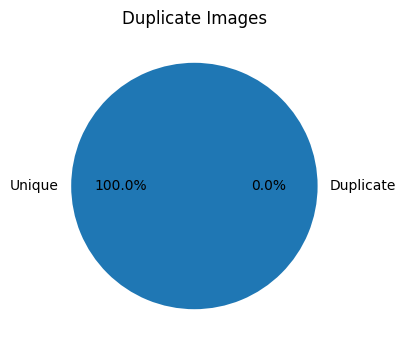


PIXEL ANALYSIS


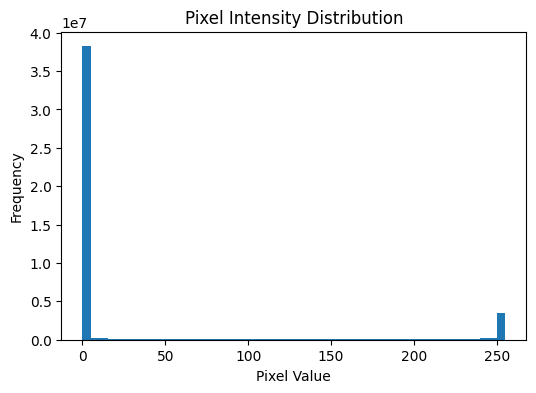


SAMPLE IMAGES


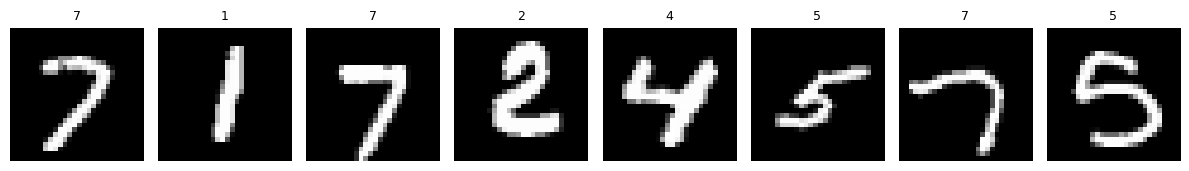


TARGET ANALYSIS
0    5923
1    6742
2    5958
3    6131
4    5842
5    5421
6    5918
7    6265
8    5851
9    5949
Name: count, dtype: int64


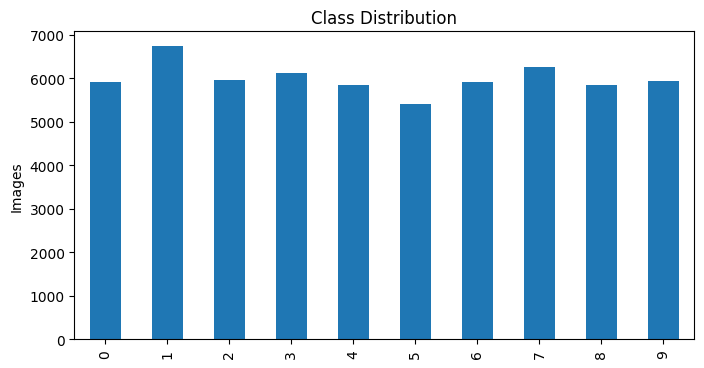


FINAL IMAGE EDA SUMMARY
Total Images        : 60000
Image Shape         : (28, 28)
Image Type          : Grayscale
Pixel Value Range   : 0 to 255
Duplicate Images    : 0
Class Balance       : Balanced

Exploratory Data Analysis Completed Successfully.


In [ ]:
image_eda(train_images, train_labels)

## 4. Data Preprocessing
Scale the pixel values and flatten each image into a single feature vector.

In [ ]:
X_train = train_images.astype("float32") / 255.0
X_test = test_images.astype("float32") / 255.0

In [ ]:
X_train = X_train.reshape(X_train.shape[0], -1)

X_test = X_test.reshape(X_test.shape[0], -1)

In [ ]:
print(X_train.shape)

(60000, 784)


## 5. Model Training

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=3)

knn.fit(X_train, train_labels)

y_pred_knn = knn.predict(X_test)

In [ ]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=1000)

lr.fit(X_train, train_labels)

y_pred_lr = lr.predict(X_test)

## 6. Model Evaluation

In [ ]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

========== KNN ==========
Accuracy : 0.9705
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       980
           1       0.96      1.00      0.98      1135
           2       0.98      0.97      0.97      1032
           3       0.96      0.97      0.96      1010
           4       0.98      0.97      0.97       982
           5       0.97      0.96      0.96       892
           6       0.98      0.99      0.98       958
           7       0.96      0.96      0.96      1028
           8       0.99      0.94      0.96       974
           9       0.96      0.96      0.96      1009

    accuracy                           0.97     10000
   macro avg       0.97      0.97      0.97     10000
weighted avg       0.97      0.97      0.97     10000



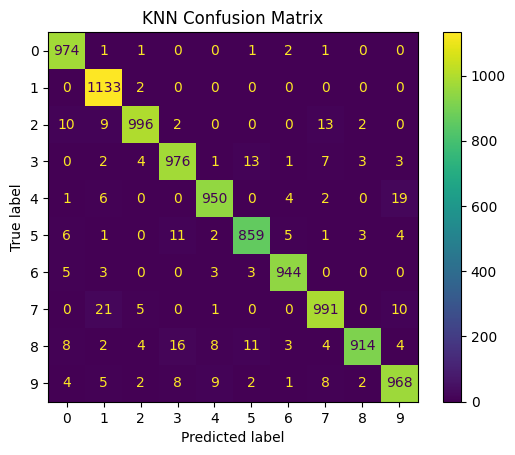

In [ ]:
print("========== KNN ==========")

print("Accuracy :", accuracy_score(test_labels, y_pred_knn))

print(classification_report(test_labels, y_pred_knn))

ConfusionMatrixDisplay.from_predictions(
    test_labels,
    y_pred_knn
)

plt.title("KNN Confusion Matrix")

plt.show()

========== Logistic Regression ==========
Accuracy : 0.9264
              precision    recall  f1-score   support

           0       0.95      0.98      0.96       980
           1       0.96      0.98      0.97      1135
           2       0.93      0.90      0.92      1032
           3       0.90      0.91      0.91      1010
           4       0.94      0.94      0.94       982
           5       0.90      0.87      0.88       892
           6       0.94      0.95      0.95       958
           7       0.94      0.92      0.93      1028
           8       0.88      0.88      0.88       974
           9       0.91      0.92      0.92      1009

    accuracy                           0.93     10000
   macro avg       0.93      0.93      0.93     10000
weighted avg       0.93      0.93      0.93     10000



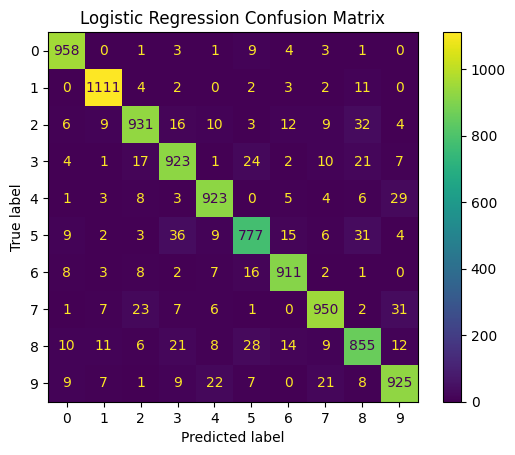

In [ ]:
print("========== Logistic Regression ==========")

print("Accuracy :", accuracy_score(test_labels, y_pred_lr))

print(classification_report(test_labels, y_pred_lr))

ConfusionMatrixDisplay.from_predictions(
    test_labels,
    y_pred_lr
)

plt.title("Logistic Regression Confusion Matrix")

plt.show()